In [1]:
from helpers import load_csv_data
from labels import x_labels

In [2]:
x_train_or, x_test_or, y_train, train_ids, test_ids = load_csv_data("./")

In [30]:
# bad_labels = ['FMONTH', 'IDATE', 'IMONTH', 'IDAY', 'DISPCODE', 'SEQNO', 'PVTRESD1', 'CELLFON3', 'CCLGHOUS', 'GENHLTH', 'MENTHLTH', 'POORHLTH', 'HLTHPLN1', 'BLOODCHO', 'CHOLCHK', 'ASTHMA3', 'CHCOCNCR', 'ADDEPEV2', 'DIABETE3', 'EDUCA', 'NUMHHOL2', 'INCOME2', 'WEIGHT2', 'QLACTLM2', 'USEEQUIP', 'DECIDE', 'DIFFWALK', 'DIFFDRES', 'DIFFALON', 'SMOKDAY2', 'STOPSMK2', 'AVEDRNK2', 'DRNK3GE5', 'MAXDRNKS', 'FRUITJU1', 'FRUIT1', 'FVBEANS', 'FVGREEN', 'VEGETAB1', 'EXERANY2', 'EXRACT21', 'EXERHMM2', 'STRENGTH', 'JOINPAIN', 'FLSHTMY2', 'IMFVPLAC', 'HIVTST6', 'PDIABTST', 'PREDIAB1', 'FEETCHK2', 'CHKHEMO3', 'FEETCHK', 'CAREGIV1', 'CRGVREL1', 'CRGVHRS1', 'CRGVMST2', 'CRGVEXPT', 'VIREDIF3', 'VIPRFVS2', 'VIEYEXM2', 'VICTRCT4', 'VIMACDG2', 'CIMEMLOS', 'CDSOCIAL', 'WTCHSALT', 'DRADVISE', 'ASATTACK', 'ASERVIST', 'ASDRVIST', 'ASYMPTOM', 'STREHAB1', 'ASPUNSAF', 'RDUCHART', 'RDUCSTRK', 'ARTTODAY', 'ARTHWGT', 'TETANUS', 'HPVADSHT', 'HADMAM', 'HOWLONG', 'HADPAP2', 'HPVTEST', 'PROFEXAM', 'LSTBLDS3', 'HADSIGM3', 'HADSGCO1', 'PSATEST1', 'PSATIME', 'PCDMDECN', 'SCNTMNY1', 'SCNTMEL1', 'SCNTPAID', 'SCNTLWK1', 'CASTHDX2', 'CASTHNO2', 'LSATISFY', 'ADSLEEP', 'ADTHINK', 'QSTVER', 'QSTLANG', 'HTIN4', 'DRNKANY5']
bad_labels = []

good_labels = ['GENHLTH', 'BPHIGH4', 'TOLDHI2', 'CVDSTRK3', 'SEX', 'EMPLOY1', 'STOPSMK2', 'PNEUVAC3', 'HAREHAB1', '_RFHLTH', '_RFHYPE5', '_RFCHOL', '_AGEG5YR', '_AGE65YR', '_AGE80', '_SMOKER3', '_RFSMOK3']
# ['_DRDXAR1', 'DRADVISE', 'CADULT', '_MRACE1', '_AGE_G', '_PASTAE1', 'ALCDAY5', 'EMPLOY1', 'BPMEDS', 'BLOODCHO', 'STOPSMK2', '_RFHYPE5', '_RFHLTH', 'CVDSTRK3', 'DRNKANY5', 'PNEUVAC3', 'FMONTH', '_HCVU651', 'DIABETE3', '_AGE65YR', '_RFSMOK3', 'TOLDHI2', '_SMOKER3', '_AGEG5YR', 'BPHIGH4', '_RFCHOL', 'SEX', '_AGE80', 'GENHLTH', 'HAREHAB1']

# cols = [i for i,l in enumerate(x_labels) if not l.endswith("_") and l not in bad_labels]
cols = [i for i,l in enumerate(x_labels) if l in good_labels]
# cols = list(range(len(x_labels)))
print(len(cols))
rem_labels = [x_labels[i] for i in cols]
x_train = x_train_or[:,cols]
x_test = x_test_or[:,cols]

17


In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np

In [32]:
imp = SimpleImputer(missing_values=np.nan, strategy="constant", fill_value=0)
x_train = imp.fit_transform(x_train)
x_test = imp.fit_transform(x_test)
no = StandardScaler()
x_train = no.fit_transform(x_train)
x_test = no.fit_transform(x_test)

In [33]:
x1_tr, x1_te, y1_tr, y1_te = train_test_split(x_train, y_train, random_state=0)
print(len(x1_tr))
print(len(x1_te))

246101
82034


In [34]:
clf = LogisticRegression(max_iter=5000, random_state=0).fit(x1_tr, y1_tr)

or_cof = clf.coef_

In [35]:
y1_pre = clf.predict_proba(x1_te)
print(np.mean(clf.predict(x1_te)))

-0.9690128483311797


In [36]:
or_loss = log_loss(y1_te, y1_pre)

print("Loss: ", or_loss)

Loss:  0.22836304732127863


In [37]:
res = permutation_importance(clf, x1_te, y1_te, scoring="neg_log_loss")

<BarContainer object of 17 artists>

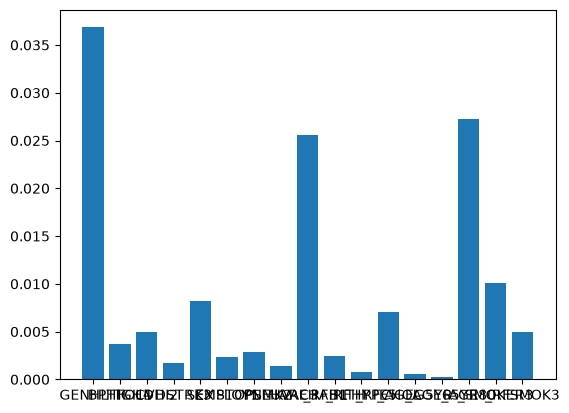

In [38]:
import matplotlib.pyplot as plt

plt.tight_layout()
plt.bar(rem_labels, res.importances_mean)

In [39]:
rel = np.argwhere(res.importances_mean > 1e-3).flatten()
print(rel)
# max_imp = np.argmax(res.importances_mean)
# args = np.argsort(res.importances_mean)
# best_imp = args[-30:]
print([rem_labels[i] for i in rel])

[ 0  1  2  3  4  5  6  7  8  9 11 14 15 16]
['GENHLTH', 'BPHIGH4', 'TOLDHI2', 'CVDSTRK3', 'SEX', 'EMPLOY1', 'STOPSMK2', 'PNEUVAC3', 'HAREHAB1', '_RFHLTH', '_RFCHOL', '_AGE80', '_SMOKER3', '_RFSMOK3']


In [40]:
bad_weights = []

for i in range(or_cof.shape[1]):
    new_cof = or_cof.copy()
    new_cof[0, i] = 0
    clf.coef_ = new_cof
    i_pre = clf.predict_proba(x1_te)
    i_loss = log_loss(y1_te, i_pre)
    if i_loss - or_loss < 1e-6:
        bad_weights.append(i)


In [41]:
print(len(bad_weights))
print([rem_labels[i] for i in bad_weights])

0
[]
